# Telecom Italia (Trentino) – Data Preparation and Cell Selection

**What this notebook does (in order)**

| # | Task | Section |
|---|---|---|
| 1 | Merge the country-code rows into one record per cell and time slot | 4 |
| 2 | Convert the raw time to local Italian time and make the data **hourly** | 4 |
| 3 | Count the unique square (cell) IDs | 5 |
| 4 | Find the cells that have all 24 hours on all 62 days, and list the cells that do not | 6 |
| 5 | Find **outlier days**: days when many cells have no records, and days with extreme traffic | 7 |
| 6 | Check whether the outlier days have a specific reason (e.g. a public holiday) | 8 |
| 7 | Select the most suitable cells (almost all data points present) and save | 9–10 |

**Raw file format** (tab-separated, no header): `CellID | time (ms since 1970, UTC) | country code | SMS-in | SMS-out | Call-in | Call-out | Internet`

The day is only in the **file name**; the files contain no date column.

## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Settings

Only change the block between the `=====` lines.

- `GAP_DAY_THRESHOLD`: a day counts as a **data-gap day** if it has fewer than this share of the normal number of records (0.90 = less than 90 %).
- `OUTLIER_Z`: a day counts as an **extreme-traffic day** if its robust z-score is beyond this value (3.5 is the usual rule of thumb).
- `MIN_COMPLETENESS`: a cell is **suitable** if it has at least this % of the hours on normal days.

In [ ]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# ============ EDIT THESE ============
DATA_DIR  = '/content/drive/MyDrive/telecom_italia/trentino_raw'   # folder with the 62 .txt files
OUT_DIR   = '/content/drive/MyDrive/telecom_italia/processed'      # results are saved here
FILE_GLOB = '*.txt'
LOCAL_TZ  = 'Europe/Rome'
GAP_DAY_THRESHOLD = 0.90
OUTLIER_Z         = 3.5
MIN_COMPLETENESS  = 99.0
# ====================================

COLS     = ['cell_id', 'ts_ms', 'country_code', 'sms_in', 'sms_out', 'call_in', 'call_out', 'internet']
ACT      = ['sms_in', 'sms_out', 'call_in', 'call_out', 'internet']   # values that are added up
USE_COLS = ['cell_id', 'ts_ms'] + ACT                                  # country_code is not read = merged

os.makedirs(f'{OUT_DIR}/daily_hourly', exist_ok=True)

## 3. List the raw files and check one file

In [ ]:
files = sorted(glob.glob(os.path.join(DATA_DIR, FILE_GLOB)))

def file_date(p):                      # the day is taken from the FILE NAME
    m = re.search(r'(\d{4}-\d{2}-\d{2})', os.path.basename(p))
    return pd.Timestamp(m.group(1)) if m else pd.NaT

inv = pd.DataFrame({'path': files})
inv['file'] = inv['path'].map(os.path.basename)
inv['date'] = inv['path'].map(file_date)

first_day, last_day = inv['date'].min(), inv['date'].max()
all_days  = pd.date_range(first_day, last_day, freq='D')
all_hours = pd.date_range(first_day, last_day + pd.Timedelta(hours=23), freq='h')
EXPECTED_HOURS = len(all_hours)

print(f'Files found : {len(inv)}  (expected 62)')
print(f'Date range  : {first_day.date()} -> {last_day.date()}')
print('Missing days:', [d.date().isoformat() for d in all_days.difference(inv['date'])] or 'none')
print(f'Expected hours per cell: {EXPECTED_HOURS}  ({len(all_days)} days x 24)')

Files found : 62  (expected 62)
Date range  : 2013-11-01 -> 2014-01-01
Missing days: none
Expected hours per cell: 1488  (62 days x 24)


In [ ]:
# Look at one raw file: format and time conversion
def has_header(path):                  # True if the first value of the first line is not a number
    with open(path) as f:
        return not f.readline().split('\t')[0].strip().isdigit()

sample = pd.read_csv(files[0], sep='\t', header=None, names=COLS, skiprows=1 if has_header(files[0]) else 0)
print('Rows                :', f'{len(sample):,}')
print('Unique cells        :', sample.cell_id.nunique())
print('Unique 10-min slots :', sample.ts_ms.nunique(), '(144 expected for a full day)')

t = pd.to_datetime(sample.ts_ms.agg(['min', 'max']), unit='ms', utc=True).dt.tz_convert(LOCAL_TZ)
print('First slot (local)  :', t['min'])
print('Last slot  (local)  :', t['max'])
sample.head()

Rows                : 2,459,324
Unique cells        : 6259
Unique 10-min slots : 144 (144 expected for a full day)
First slot (local)  : 2013-11-01 00:00:00+01:00
Last slot  (local)  : 2013-11-01 23:50:00+01:00


,cell_id,ts_ms,country_code,sms_in,sms_out,call_in,call_out,internet
0,10000,1383260400000,0,0.109442,NaN,NaN,0.021888,NaN
1,10000,1383260400000,39,1.000626,1.264627,0.087554,0.219587,10.168455
2,10000,1383260400000,49,NaN,NaN,NaN,NaN,0.021888
3,10000,1383261000000,0,0.193200,NaN,NaN,NaN,NaN
4,10000,1383261000000,39,0.648294,1.058651,0.175108,0.153219,11.867058


## 4. Merge country codes and convert to hourly

For **each day file**, `process_file()` does:

1. **Read** the file. The country-code column is not read.
2. **Merge country codes**: add up all rows with the same `(cell_id, ts_ms)`, so there is one record per cell and 10-minute slot.
3. **Convert time**: raw milliseconds → UTC → Europe/Rome local time → round **down** to the hour (14:30 and 14:50 both become 14:00).
4. **Hourly**: add up the 10-minute values of each `(cell, hour)`.

> An empty value in the raw file means no activity was recorded, so it is counted as 0 when summed. `n_slots` (how many 10-minute records were in the hour) is stored for reference.

Each day is saved to Drive after it is processed. If Colab disconnects, run the cell again and it **continues** where it stopped.

In [ ]:
def process_file(path):
    # 1. read (country_code column skipped)
    df = pd.read_csv(path, sep='\t', header=None, names=COLS, usecols=USE_COLS,
                     skiprows=1 if has_header(path) else 0)
    df['cell_id'] = df['cell_id'].astype('int32')

    # 2. merge country codes -> one record per cell and 10-min slot
    g = df.groupby(['cell_id', 'ts_ms'], sort=False)[ACT].sum().reset_index()

    # 3. time conversion (done on the ~144 distinct timestamps only, which is fast)
    uniq  = g['ts_ms'].unique()
    local = pd.to_datetime(uniq, unit='ms', utc=True).tz_convert(LOCAL_TZ).tz_localize(None)
    g['hour'] = g['ts_ms'].map(dict(zip(uniq, local))).dt.floor('h')

    # 4. 10-minute -> hourly
    agg = {c: 'sum' for c in ACT}
    agg['ts_ms'] = 'size'
    h = (g.groupby(['cell_id', 'hour'], sort=False).agg(agg)
           .rename(columns={'ts_ms': 'n_slots'}).reset_index())
    h[ACT] = h[ACT].astype('float32')
    h['n_slots'] = h['n_slots'].astype('int8')
    return h

for p in tqdm(files, desc='Processing days'):
    out = os.path.join(OUT_DIR, 'daily_hourly', os.path.basename(p).rsplit('.', 1)[0] + '.parquet')
    if not os.path.exists(out):          # skip days that are already done
        process_file(p).to_parquet(out, index=False)

print('Daily hourly files on Drive:', len(os.listdir(f'{OUT_DIR}/daily_hourly')))

Processing days:   0%|          | 0/62 [00:00<?, ?it/s]

Daily hourly files on Drive: 62


## 5. Combine all days and count the cells

All daily files are joined into one table `hourly` (one row per **cell and hour**).

Safety check: a few raw records can carry a wrong time value (for example `0`, which becomes **1970-01-01**). Any hour outside the 62 file dates is removed and reported here, so no 1970 date can enter the analysis.

In [ ]:
parts  = sorted(glob.glob(f'{OUT_DIR}/daily_hourly/*.parquet'))
hourly = pd.concat([pd.read_parquet(p, columns=['cell_id', 'hour'] + ACT) for p in tqdm(parts, desc='Loading')],
                   ignore_index=True)

# remove hours outside the date range of the files (bad timestamps)
bad = (hourly['hour'] < first_day) | (hourly['hour'] >= last_day + pd.Timedelta(days=1))
print(f'Rows with a time outside {first_day.date()} -> {last_day.date()} removed: {bad.sum():,}')
if bad.any():
    print(hourly.loc[bad, 'hour'].dt.date.value_counts().head())
hourly = hourly[~bad]

# an hour split across two files would appear twice -> merge (normally 0)
dups = hourly.duplicated(['cell_id', 'hour']).sum()
print('Duplicate (cell, hour) rows:', dups)
if dups:
    hourly = hourly.groupby(['cell_id', 'hour'], as_index=False)[ACT].sum()

hourly = hourly.sort_values(['cell_id', 'hour']).reset_index(drop=True)
hourly['date'] = hourly['hour'].dt.normalize()

print(f'\nHourly table  : {len(hourly):,} rows')
print(f'Unique cells (square IDs) : {hourly.cell_id.nunique():,}')
print(f'Cell ID range             : {hourly.cell_id.min()} -> {hourly.cell_id.max()}')
hourly.head()

Loading:   0%|          | 0/62 [00:00<?, ?it/s]

Rows with a time outside 2013-11-01 -> 2014-01-01 removed: 1
hour
1970-01-01    1
Name: count, dtype: int64
Duplicate (cell, hour) rows: 0

Hourly table  : 9,076,016 rows
Unique cells (square IDs) : 6,259
Cell ID range             : 38 -> 11454


,cell_id,hour,sms_in,sms_out,call_in,call_out,internet,date
0,38,2013-11-01 00:00:00,3.230043,2.702733,0.547075,0.103967,59.390484,2013-11-01
1,38,2013-11-01 01:00:00,1.097136,2.739491,0.033146,0.019763,53.550552,2013-11-01
2,38,2013-11-01 02:00:00,1.001065,2.334906,0.414200,0.238357,56.370071,2013-11-01
3,38,2013-11-01 03:00:00,0.330291,1.296179,0.108073,0.000000,54.443085,2013-11-01
4,38,2013-11-01 04:00:00,0.595967,0.820119,0.104597,0.033146,50.946915,2013-11-01


## 6. Which cells have all 24 hours on all 62 days?

`cd` has one row per cell and one column per day, with the **number of hours present** that day (24 = complete day).
A cell is **complete** only if it has 24 hours on **every** day (1,488 hours).

In [ ]:
cd = (hourly.groupby(['cell_id', 'date']).size().unstack('date')
            .reindex(columns=all_days).fillna(0).astype('int16'))

report = pd.DataFrame(index=cd.index)
report.index.name = 'cell_id'
report['hours_present']     = cd.sum(axis=1)
report['hours_missing']     = EXPECTED_HOURS - report['hours_present']
report['days_with_all_24h'] = (cd == 24).sum(axis=1)
report['complete']          = report['days_with_all_24h'] == len(all_days)

complete_cells   = report.index[report.complete]
incomplete_cells = report.index[~report.complete]

print(f'Total cells                                  : {len(report):,}')
print(f'Cells with all 24 h on all {len(all_days)} days            : {len(complete_cells):,}')
print(f'Cells missing at least one hour              : {len(incomplete_cells):,}')

print('\nIncomplete cells, most missing hours first:')
display(report.loc[incomplete_cells].sort_values('hours_missing', ascending=False).head(15))

Total cells                                  : 6,259
Cells with all 24 h on all 62 days            : 171
Cells missing at least one hour              : 6,088

Incomplete cells, most missing hours first:


,hours_present,hours_missing,days_with_all_24h,complete
cell_id,,,,
7586,922,566,16,False
7110,922,566,16,False
7111,922,566,16,False
7112,922,566,16,False
6993,922,566,16,False
6995,922,566,16,False
7585,922,566,16,False
7467,922,566,16,False
7232,922,566,16,False


## 7. Outlier days

Two kinds of outliers are looked for. Both are found **from the data only** (no holiday list is used here).

**A. Data-gap days.** Count the hourly records per day. A normal day has about the same number every day. If a day has far fewer records (below `GAP_DAY_THRESHOLD` of the median day), many cells have no data that day.

**B. Extreme-traffic days.** For this we use only the cells that have complete data on all 62 days (`complete_cells`), so every day contains the same cells and the daily totals can be compared fairly. The **robust z-score** compares each day with the median day: `0.6745 × (day − median) / MAD`. Values beyond `OUTLIER_Z` (default 3.5) are extreme, high or low.

In [ ]:
day_tbl = pd.DataFrame({
    'cells_reporting': hourly.groupby('date')['cell_id'].nunique(),
    'records':         hourly.groupby('date').size(),
}).reindex(all_days)

# A. data-gap days
day_tbl['records_vs_normal_pct'] = (100 * day_tbl['records'] / day_tbl['records'].median()).round(1)
day_tbl['data_gap'] = day_tbl['records_vs_normal_pct'] < 100 * GAP_DAY_THRESHOLD

# B. extreme-traffic days (cells that are complete on all days)
print(f'Reference cells used for daily traffic: {len(complete_cells)}')
ref = hourly[hourly['cell_id'].isin(complete_cells)]
day_tbl['traffic'] = ref.groupby('date')['internet'].sum().reindex(all_days)

med = day_tbl['traffic'].median()
mad = (day_tbl['traffic'] - med).abs().median()
day_tbl['traffic_vs_median'] = (day_tbl['traffic'] / med).round(2)
day_tbl['robust_z'] = (0.6745 * (day_tbl['traffic'] - med) / mad).round(1) if mad > 0 else 0.0
day_tbl['high_traffic'] = day_tbl['robust_z'] >  OUTLIER_Z
day_tbl['low_traffic']  = day_tbl['robust_z'] < -OUTLIER_Z

day_tbl['weekday'] = day_tbl.index.day_name()
def outlier_type(r):
    t = []
    if r.data_gap:     t.append('DATA GAP')
    if r.high_traffic: t.append('HIGH TRAFFIC')
    if r.low_traffic:  t.append('LOW TRAFFIC')
    return ' + '.join(t)
day_tbl['type'] = day_tbl.apply(outlier_type, axis=1)

outliers = day_tbl[day_tbl['type'] != '']
print(f'\nOutlier days found: {len(outliers)}')
display(outliers[['weekday', 'type', 'cells_reporting', 'records_vs_normal_pct', 'traffic_vs_median', 'robust_z']])

Reference cells used for daily traffic: 171

Outlier days found: 14


,weekday,type,cells_reporting,records_vs_normal_pct,traffic_vs_median,robust_z
2013-12-05,Thursday,DATA GAP,4036,64.5,0.99,-0.100000
2013-12-19,Thursday,DATA GAP,176,2.8,1.08,0.700000
2013-12-21,Saturday,HIGH TRAFFIC,6259,100.1,1.43,3.900000
2013-12-22,Sunday,HIGH TRAFFIC,6259,100.1,1.58,5.300000
2013-12-23,Monday,HIGH TRAFFIC,6259,100.1,1.65,6.000000
2013-12-24,Tuesday,HIGH TRAFFIC,6259,100.1,1.67,6.100000
2013-12-25,Wednesday,HIGH TRAFFIC,6259,100.1,1.76,7.000000
2013-12-26,Thursday,HIGH TRAFFIC,6259,100.0,2.05,9.600000
2013-12-27,Friday,HIGH TRAFFIC,6240,99.3,2.46,13.400000
2013-12-28,Saturday,HIGH TRAFFIC,6259,99.7,2.80,16.600000


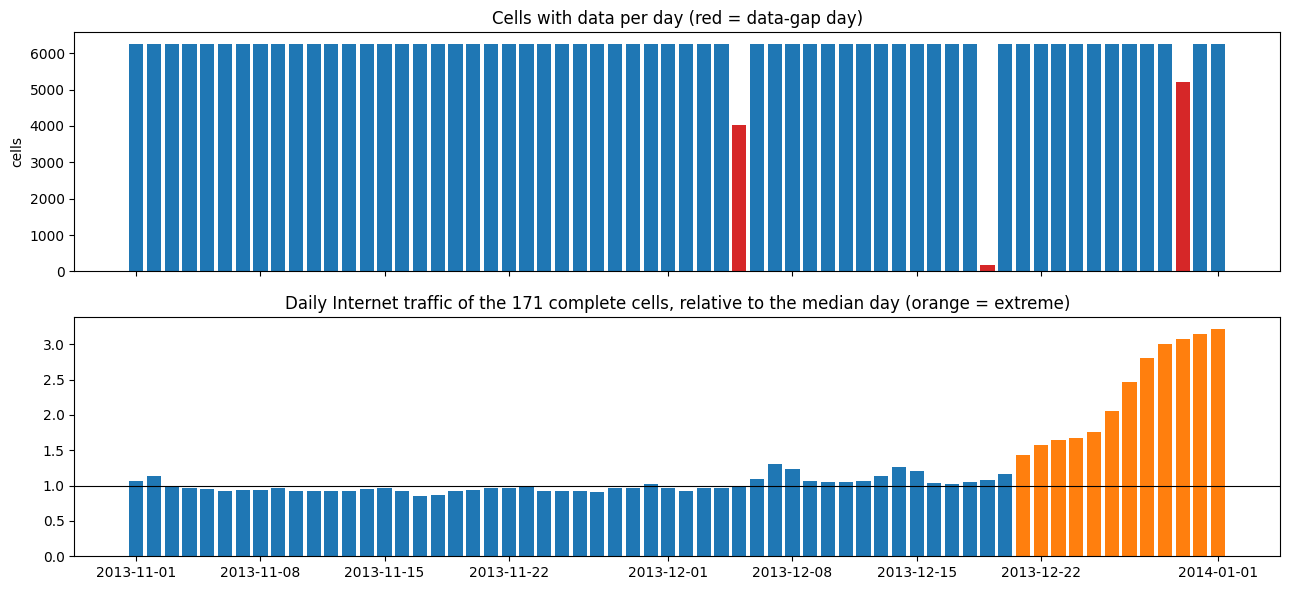

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

ax[0].bar(day_tbl.index, day_tbl['cells_reporting'],
          color=np.where(day_tbl['data_gap'], 'tab:red', 'tab:blue'), width=0.8)
ax[0].set_title('Cells with data per day (red = data-gap day)'); ax[0].set_ylabel('cells')

ax[1].bar(day_tbl.index, day_tbl['traffic_vs_median'],
          color=np.where(day_tbl['high_traffic'] | day_tbl['low_traffic'], 'tab:orange', 'tab:blue'), width=0.8)
ax[1].axhline(1, color='k', lw=0.8)
ax[1].set_title(f'Daily Internet traffic of the {len(complete_cells)} complete cells, relative to the median day (orange = extreme)')
plt.tight_layout(); plt.show()

plot 1-one bar per day, the number of cells (out of 6,259) with at least one record that day. Blue is normal, and red marks the data-gap days: Dec 5 (4,036 cells), Dec 19 (176) and Dec 30 (5,197).


plot two -one bar per day, the total Internet traffic of the 171 complete cells divided by the median day. The line at 1.0 is a typical day, and 1.5 means 50% above typical. Orange marks the extreme days (Dec 21 – Jan 1), where traffic climbs from about 1.4× to 3.2×.

## 8. Is there a reason for the outlier days?

Now we look at the outlier days found above and check them against possible explanations. This is **only a check after detection**; the list below was not used to find the outliers.

How to read it:
- `weekday`: is the outlier on a weekend?
- `public_holiday`: does it fall on an Italian public holiday? (Reference list for the period, edit if needed.)
- `days_to_nearest_holiday`: is it close to a holiday (for example a bridge day or holiday week)?

A **data-gap day** with no matching holiday or weekend is most likely a problem in data collection, not real customer behaviour.

In [ ]:
# Reference only: Italian public holidays inside the data period (not used to detect outliers)
italian_holidays = {'2013-11-01': 'All Saints', '2013-12-08': 'Immaculate Conception',
                    '2013-12-25': 'Christmas Day', '2013-12-26': "St Stephen's Day",
                    '2014-01-01': "New Year's Day"}
hol_dates = pd.to_datetime(list(italian_holidays))

check = outliers[['weekday', 'type', 'traffic_vs_median']].copy()
check['public_holiday'] = [italian_holidays.get(d.strftime('%Y-%m-%d'), '') for d in check.index]
check['days_to_nearest_holiday'] = [int(min(abs((d - hol_dates).days))) for d in check.index]
display(check)

print('\nFor comparison, how did the holiday days themselves look?')
hol_view = day_tbl.loc[day_tbl.index.isin(hol_dates), ['weekday', 'traffic_vs_median', 'cells_reporting']].copy()
hol_view['holiday'] = [italian_holidays[d.strftime('%Y-%m-%d')] for d in hol_view.index]
display(hol_view)

,weekday,type,traffic_vs_median,public_holiday,days_to_nearest_holiday
2013-12-05,Thursday,DATA GAP,0.99,,3
2013-12-19,Thursday,DATA GAP,1.08,,6
2013-12-21,Saturday,HIGH TRAFFIC,1.43,,4
2013-12-22,Sunday,HIGH TRAFFIC,1.58,,3
2013-12-23,Monday,HIGH TRAFFIC,1.65,,2
2013-12-24,Tuesday,HIGH TRAFFIC,1.67,,1
2013-12-25,Wednesday,HIGH TRAFFIC,1.76,Christmas Day,0
2013-12-26,Thursday,HIGH TRAFFIC,2.05,St Stephen's Day,0
2013-12-27,Friday,HIGH TRAFFIC,2.46,,1
2013-12-28,Saturday,HIGH TRAFFIC,2.80,,2



For comparison, how did the holiday days themselves look?


,weekday,traffic_vs_median,cells_reporting,holiday
2013-11-01,Friday,1.06,6259,All Saints
2013-12-08,Sunday,1.24,6259,Immaculate Conception
2013-12-25,Wednesday,1.76,6259,Christmas Day
2013-12-26,Thursday,2.05,6259,St Stephen's Day
2014-01-01,Wednesday,3.22,6258,New Year's Day


## 9. Select the most suitable cells

Data-gap days affect almost every cell, so they must not count against a single cell. Each cell is therefore judged only on the **normal days** (all days except the data-gap days).

- **perfect**: no missing hour on normal days
- **suitable**: at least `MIN_COMPLETENESS` % of the hours on normal days present

Data-gap days excluded: ['2013-12-05', '2013-12-19', '2013-12-30']
Normal hours per cell : 1416

Total cells                              : 6,259
Perfect cells (no missing normal hour)   : 6,039  (96.5 %)
Suitable cells (>= 99% of normal hours)    : 6,152  (98.3 %)
Not suitable                             : 107

Least complete cells:


,hours_present_normal,hours_missing_normal,completeness_normal_pct
cell_id,,,
7467,898,518,63.42
7585,898,518,63.42
7586,898,518,63.42
6993,898,518,63.42
6995,898,518,63.42
7232,898,518,63.42
7235,898,518,63.42
7233,898,518,63.42
7110,898,518,63.42


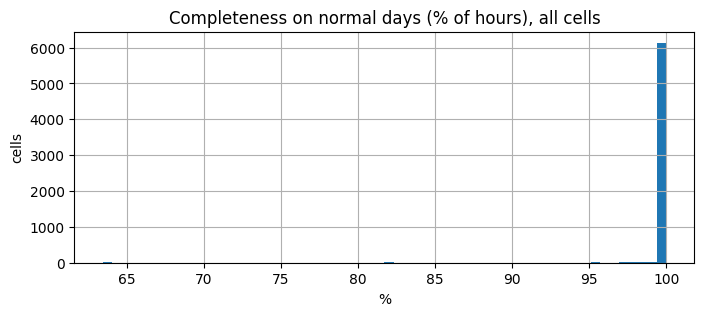

In [ ]:
gap_days = list(day_tbl.index[day_tbl['data_gap']])
n_normal_hours = (len(all_days) - len(gap_days)) * 24
print(f'Data-gap days excluded: {[d.date().isoformat() for d in gap_days]}')
print(f'Normal hours per cell : {n_normal_hours}')

normal_rows = hourly[~hourly['date'].isin(gap_days)]
report['hours_present_normal'] = normal_rows.groupby('cell_id').size().reindex(report.index).fillna(0).astype(int)
report['hours_missing_normal'] = n_normal_hours - report['hours_present_normal']
report['completeness_normal_pct'] = (100 * report['hours_present_normal'] / n_normal_hours).round(2)

perfect  = report.index[report.hours_missing_normal == 0]
suitable = report.index[report.completeness_normal_pct >= MIN_COMPLETENESS]
not_suitable = report.index.difference(suitable)

print(f'\nTotal cells                              : {len(report):,}')
print(f'Perfect cells (no missing normal hour)   : {len(perfect):,}  ({100*len(perfect)/len(report):.1f} %)')
print(f'Suitable cells (>= {MIN_COMPLETENESS:.0f}% of normal hours)    : {len(suitable):,}  ({100*len(suitable)/len(report):.1f} %)')
print(f'Not suitable                             : {len(not_suitable):,}')

print('\nLeast complete cells:')
display(report.sort_values('completeness_normal_pct').head(15)[['hours_present_normal', 'hours_missing_normal', 'completeness_normal_pct']])

report['completeness_normal_pct'].hist(bins=60, figsize=(8, 3))
plt.title('Completeness on normal days (% of hours), all cells'); plt.xlabel('%'); plt.ylabel('cells'); plt.show()

## 10. Save the results

| File | Content |
|---|---|
| `hourly_all_cells.parquet` | hourly table, all cells |
| `cell_report.csv` | per-cell completeness (all days and normal days) |
| `complete_cells_all_days.csv` | cells with all 24 h on all 62 days |
| `incomplete_cells.csv` | cells missing at least one hour |
| `outlier_days.csv` | the outlier days found |
| `selected_cells.csv` | suitable cells (use these for modelling) |
| `hourly_selected_cells.parquet` | full cell × hour table for the suitable cells; missing hours are **empty (NaN)**, not zero, with flags `is_missing` and `is_gap_day` |

> Missing hours are kept as NaN because a data-gap day is lost data, not zero traffic. How to handle them is decided in the modelling step.

In [ ]:
hourly.drop(columns='date').to_parquet(f'{OUT_DIR}/hourly_all_cells.parquet', index=False)
report.to_csv(f'{OUT_DIR}/cell_report.csv')
pd.Series(complete_cells,   name='cell_id').to_csv(f'{OUT_DIR}/complete_cells_all_days.csv', index=False)
pd.Series(incomplete_cells, name='cell_id').to_csv(f'{OUT_DIR}/incomplete_cells.csv', index=False)
outliers.to_csv(f'{OUT_DIR}/outlier_days.csv')
pd.Series(suitable, name='cell_id').to_csv(f'{OUT_DIR}/selected_cells.csv', index=False)

# full cell x hour table for the suitable cells (missing hours = NaN)
idx = pd.MultiIndex.from_product([sorted(suitable), all_hours], names=['cell_id', 'hour'])
grid = (hourly[hourly['cell_id'].isin(suitable)].set_index(['cell_id', 'hour'])[ACT]
              .reindex(idx).reset_index())
grid['is_missing'] = grid['internet'].isna()
grid['is_gap_day'] = grid['hour'].dt.normalize().isin(gap_days)
grid.to_parquet(f'{OUT_DIR}/hourly_selected_cells.parquet', index=False)

print(f'Selected-cell table: {len(grid):,} rows, missing share {100*grid.is_missing.mean():.2f} %')
print(sorted(f for f in os.listdir(OUT_DIR) if f != 'daily_hourly'))

Selected-cell table: 9,154,176 rows, missing share 2.40 %
['cell_report.csv', 'complete_cells_all_days.csv', 'hourly_all_cells.parquet', 'hourly_selected_cells.parquet', 'incomplete_cells.csv', 'outlier_days.csv', 'selected_cells.csv']


## Summary

Fill in from the outputs above:

- Unique square IDs: section 5
- Cells with all 24 h on all 62 days / cells that are not complete: section 6
- Outlier days and their possible reasons: sections 7 and 8
- Suitable cells for modelling: section 9 (`selected_cells.csv`)

The data analysis (patterns, seasonality, choosing the 300 modelling cells) comes next, using `hourly_selected_cells.parquet`.